# Databricks EDA — `banking_transactions_db.public`
Tables view, dtypes, null counts, distributions, trends and boxplots (seaborn + matplotlib).

In [1]:
import os
import sys

sys.path.insert(0, os.path.abspath(".."))  # repo root

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from contextlib import contextmanager

from src.utils.connection import get_databricks_connection


@contextmanager
def databricks_cursor():
    conn = get_databricks_connection()
    cur = conn.cursor()
    try:
        yield cur
    finally:
        cur.close()
        conn.close()

sns.set_theme(style="whitegrid")


def dbx_df(sql, params=None):
    with databricks_cursor() as cur:
        cur.execute(sql, params or [])
        rows = cur.fetchall()
        cols = [d[0] for d in cur.description]
    return pd.DataFrame(rows, columns=cols)


print("connected")

connected


## 1. Tables view

In [2]:
meta = dbx_df("SHOW TABLES IN banking_transactions_db.public")
meta.columns = ["db", "table", "is_temp"]
meta["rows"] = [dbx_df(f"SELECT COUNT(*) AS c FROM banking_transactions_db.public.{t}").iloc[0, 0]
                for t in meta["table"]]
display(meta)

,db,table,is_temp,rows
0,public,loan_payments,False,600000
1,public,loans,False,22000
2,public,transactions,False,2000000


## 2. Load data (50k samples for the two large tables)

In [3]:
loans = dbx_df("SELECT * FROM banking_transactions_db.public.loans")
payments = dbx_df("SELECT * FROM banking_transactions_db.public.loan_payments LIMIT 50000")
txns = dbx_df("SELECT * FROM banking_transactions_db.public.transactions LIMIT 50000")
for d in (loans, payments, txns):
    for c in d.columns:
        if "date" in c or "_at" in c:
            d[c] = pd.to_datetime(d[c], errors="coerce")
print("loans:", loans.shape, "| payments sample:", payments.shape, "| txns sample:", txns.shape)

loans: (22000, 11) | payments sample: (50000, 9) | txns sample: (50000, 9)


In [4]:
def profile(df, name, plot_n=5000):
    """Shape, dtypes, nulls + missing bar and numeric boxplots."""
    print(f"--- {name} ---")
    print("shape:", df.shape)
    print(pd.DataFrame({"dtype": df.dtypes.astype(str), "nulls": df.isna().sum(),
                        "null_pct": (df.isna().mean() * 100).round(2)}))
    display(df.head(3))
    display(df.describe(include="all").T)
    miss = (df.isna().mean() * 100).round(2)
    miss = miss[miss > 0].sort_values()
    if len(miss):
        fig, ax = plt.subplots(figsize=(8, max(3, len(miss) * 0.4)))
        miss.plot.barh(ax=ax, color="tomato")
        ax.set_title(f"{name}: missing values (%)")
        ax.set_xlabel("% missing")
        plt.tight_layout(); plt.show()
    else:
        print("no missing values")
    num = df.select_dtypes(include="number").columns.tolist()
    if num:
        p = df[num].sample(n=min(plot_n, len(df)), random_state=42)
        fig, axes = plt.subplots(1, len(num), figsize=(4 * len(num), 4))
        if len(num) == 1:
            axes = [axes]
        for a, c in zip(axes, num):
            sns.boxplot(y=p[c], ax=a)
            a.set_title(c)
        fig.suptitle(f"{name}: numeric boxplots (n={len(p)})")
        plt.tight_layout(); plt.show()
    return df.shape

### loans

--- loans ---
shape: (22000, 11)
                                 dtype  nulls  null_pct
loan_id                          int64      0       0.0
customer_id                      int64      0       0.0
branch_id                        int64      0       0.0
loan_type                          str      0       0.0
loan_amount                    float64      0       0.0
interest_rate                  float64      0       0.0
term_months                      int64      0       0.0
start_date               datetime64[s]      0       0.0
status                             str      0       0.0
loaded_at      datetime64[us, Etc/UTC]      0       0.0
created_at     datetime64[us, Etc/UTC]      0       0.0


,loan_id,customer_id,branch_id,loan_type,loan_amount,interest_rate,term_months,start_date,status,loaded_at,created_at
0,1,48019,129,Auto Loan,310670.27,9.54,60,2020-06-16,Active,2026-10-16 06:22:31.768933+00:00,2026-10-16 06:22:31.768933+00:00
1,2,47355,38,Education Loan,599321.65,16.20,12,2016-06-05,Active,2026-10-16 06:22:31.768933+00:00,2026-10-16 06:22:31.768933+00:00
2,3,30661,29,Gold Loan,135377.18,10.25,24,2012-07-03,Active,2026-10-16 06:22:31.768933+00:00,2026-10-16 06:22:31.768933+00:00


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
loan_id,22000.0,NaN,NaN,NaN,11000.5,1.0,5500.75,11000.5,16500.25,22000.0,6350.997297
customer_id,22000.0,NaN,NaN,NaN,30052.203045,1.0,14923.0,29977.0,45099.75,59999.0,17392.068362
branch_id,22000.0,NaN,NaN,NaN,75.677818,1.0,38.0,76.0,113.0,150.0,43.220947
loan_type,22000,6,Education Loan,3702,NaN,NaN,NaN,NaN,NaN,NaN,NaN
loan_amount,22000.0,NaN,NaN,NaN,418847.621626,20001.65,135240.7225,296882.865,575823.555,4016132.25,395760.076367
interest_rate,22000.0,NaN,NaN,NaN,11.51176,6.5,9.03,11.5,14.02,16.5,2.884198
term_months,22000.0,NaN,NaN,NaN,95.041091,12.0,24.0,84.0,180.0,240.0,75.721432
start_date,22000,NaN,NaN,NaN,2017-09-12 22:01:27,2010-01-01 00:00:00,2013-11-21 00:00:00,2017-09-16 12:00:00,2021-07-05 00:00:00,2025-05-31 00:00:00,NaN
status,22000,4,Active,14320,NaN,NaN,NaN,NaN,NaN,NaN,NaN
loaded_at,22000,NaN,NaN,NaN,2026-10-16 06:22:31.768932+00:00,2026-10-16 06:22:31.768933+00:00,2026-10-16 06:22:31.768933+00:00,2026-10-16 06:22:31.768933+00:00,2026-10-16 06:22:31.768933+00:00,2026-10-16 06:22:31.768933+00:00,NaN


no missing values


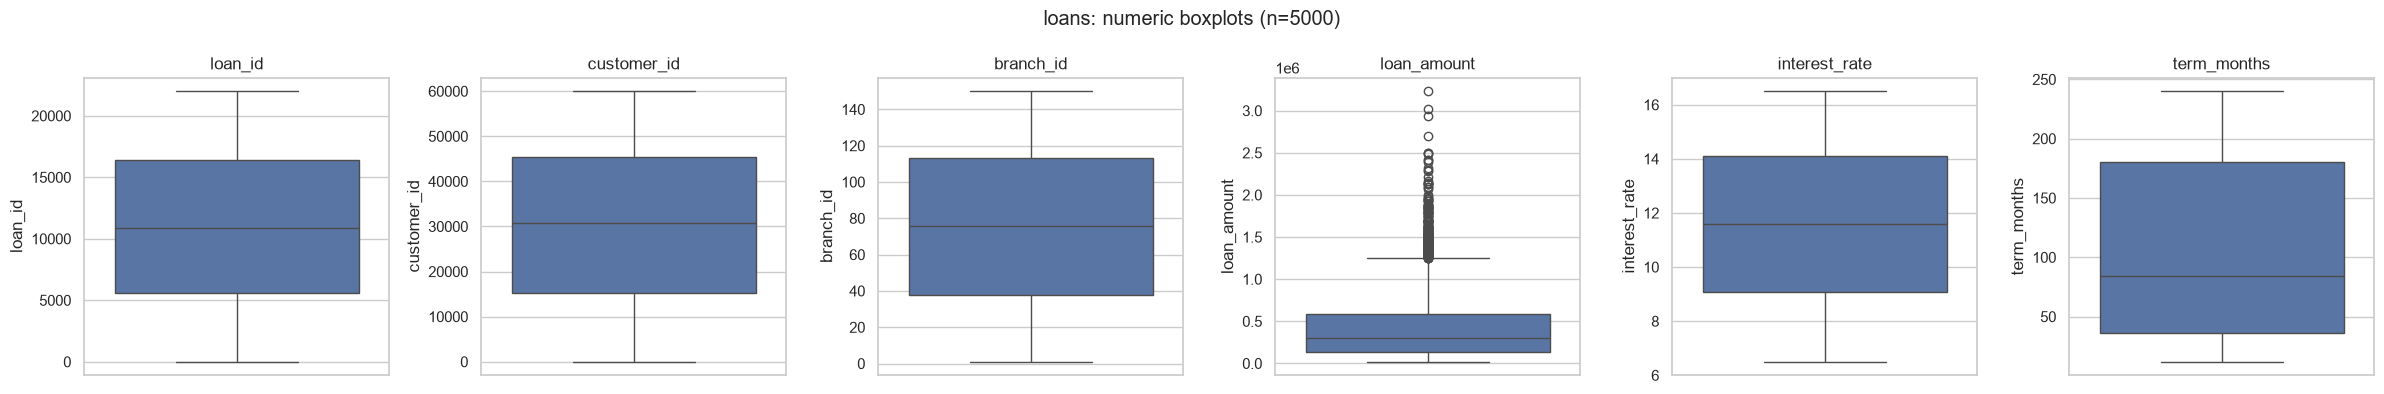

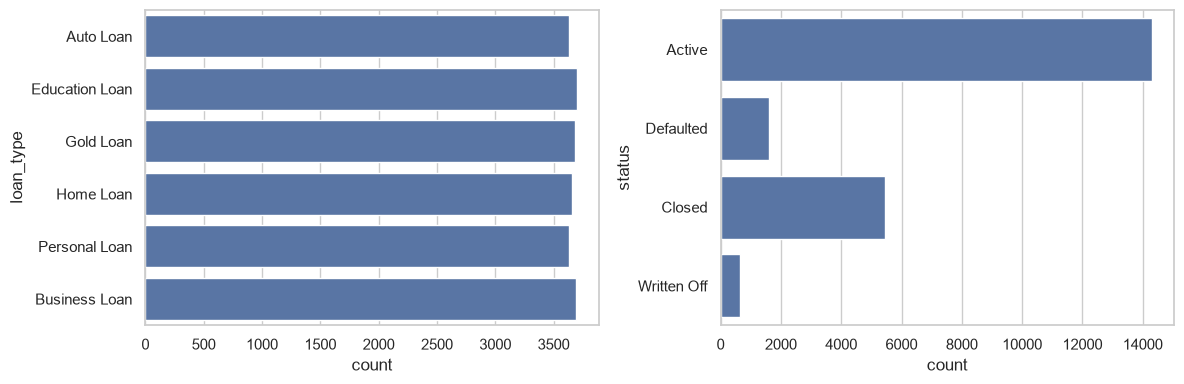

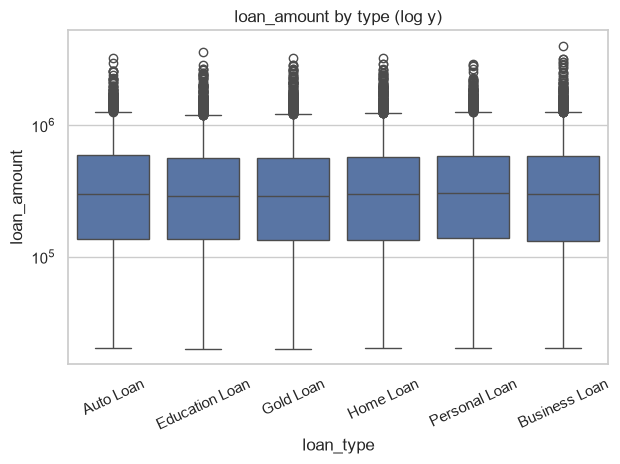

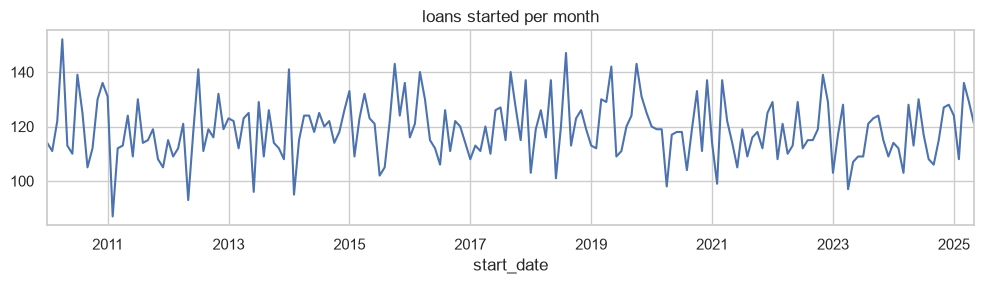

In [5]:
profile(loans, "loans")
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(y=loans["loan_type"], ax=axes[0])
sns.countplot(y=loans["status"], ax=axes[1])
plt.tight_layout(); plt.show()
sns.boxplot(data=loans, x="loan_type", y="loan_amount")
plt.yscale("log"); plt.xticks(rotation=25)
plt.title("loan_amount by type (log y)"); plt.tight_layout(); plt.show()
loans.set_index("start_date").resample("ME").size().plot(figsize=(10, 3), title="loans started per month")
plt.tight_layout(); plt.show()

### loan_payments (50k sample)

--- loan_payments ---
shape: (50000, 9)
                                       dtype  nulls  null_pct
payment_id                             int64      0       0.0
loan_id                                int64      0       0.0
payment_date                   datetime64[s]      0       0.0
amount_paid                          float64      0       0.0
principal_component                  float64      0       0.0
interest_component                   float64      0       0.0
late_payment_flag                      int64      0       0.0
loaded_at            datetime64[us, Etc/UTC]      0       0.0
created_at           datetime64[us, Etc/UTC]      0       0.0


,payment_id,loan_id,payment_date,amount_paid,principal_component,interest_component,late_payment_flag,loaded_at,created_at
0,1,21070,2020-05-06,8144.05,5930.89,2213.16,0,2026-10-16 06:22:35.262093+00:00,2026-10-16 06:22:35.262093+00:00
1,2,17959,2011-09-23,6128.01,4406.78,1721.23,0,2026-10-16 06:22:35.262093+00:00,2026-10-16 06:22:35.262093+00:00
2,3,7239,2025-02-25,27946.17,25195.76,2750.41,0,2026-10-16 06:22:35.262093+00:00,2026-10-16 06:22:35.262093+00:00


,count,mean,min,25%,50%,75%,max,std
payment_id,50000.0,25000.5,1.0,12500.75,25000.5,37500.25,50000.0,14433.901067
loan_id,50000.0,10956.15918,1.0,5481.0,10955.0,16410.0,21998.0,6334.0341
payment_date,50000,2018-04-04 01:50:37,2010-02-01 00:00:00,2014-03-06 00:00:00,2018-04-09 00:00:00,2022-04-30 00:00:00,2026-05-31 00:00:00,NaN
amount_paid,50000.0,10396.484973,533.81,3434.915,7402.24,14111.8175,130646.53,9787.867803
principal_component,50000.0,8479.447985,500.08,2825.8675,6052.535,11558.54,94528.43,7921.451062
interest_component,50000.0,1917.036989,26.03,511.1775,1192.82,2513.7,36118.1,2145.172557
late_payment_flag,50000.0,0.11956,0.0,0.0,0.0,0.0,1.0,0.32445
loaded_at,50000,2026-10-16 06:22:35.262092+00:00,2026-10-16 06:22:35.262093+00:00,2026-10-16 06:22:35.262093+00:00,2026-10-16 06:22:35.262093+00:00,2026-10-16 06:22:35.262093+00:00,2026-10-16 06:22:35.262093+00:00,NaN
created_at,50000,2026-10-16 06:22:35.262092+00:00,2026-10-16 06:22:35.262093+00:00,2026-10-16 06:22:35.262093+00:00,2026-10-16 06:22:35.262093+00:00,2026-10-16 06:22:35.262093+00:00,2026-10-16 06:22:35.262093+00:00,NaN


no missing values


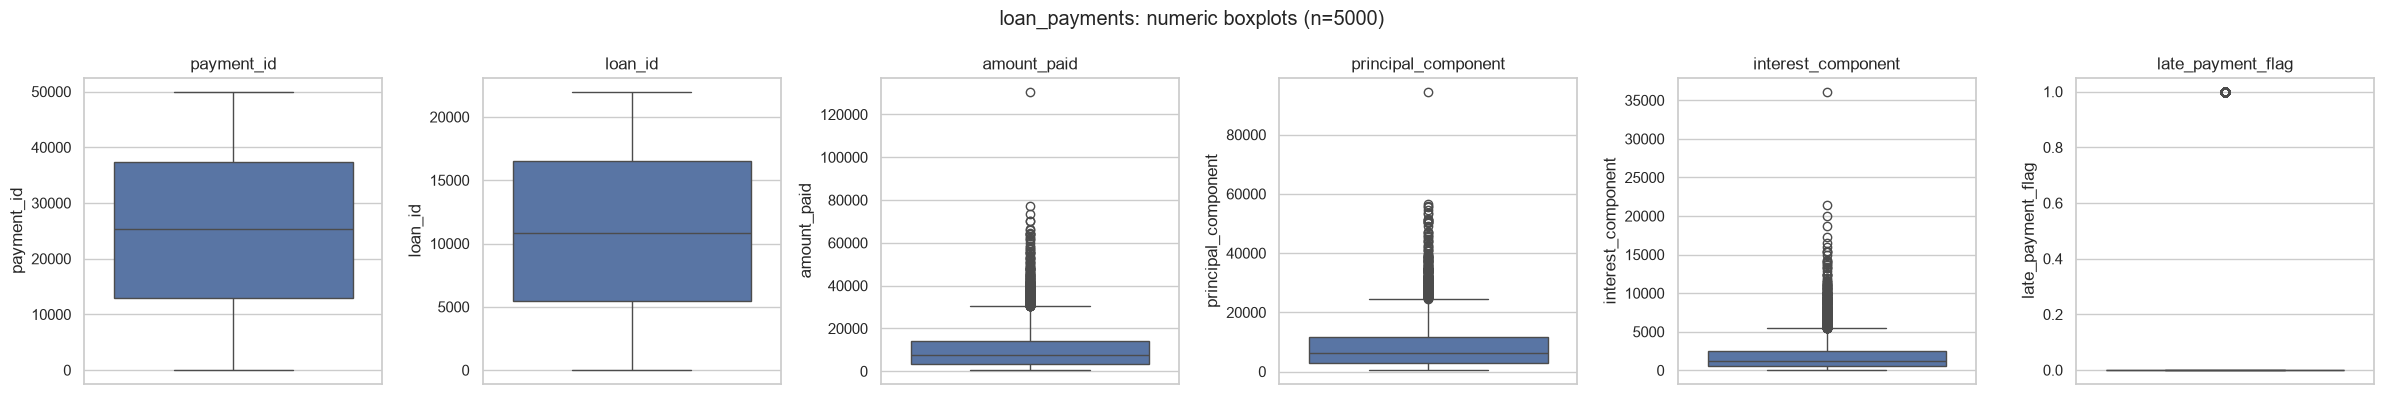

late-payment rate: 0.1196


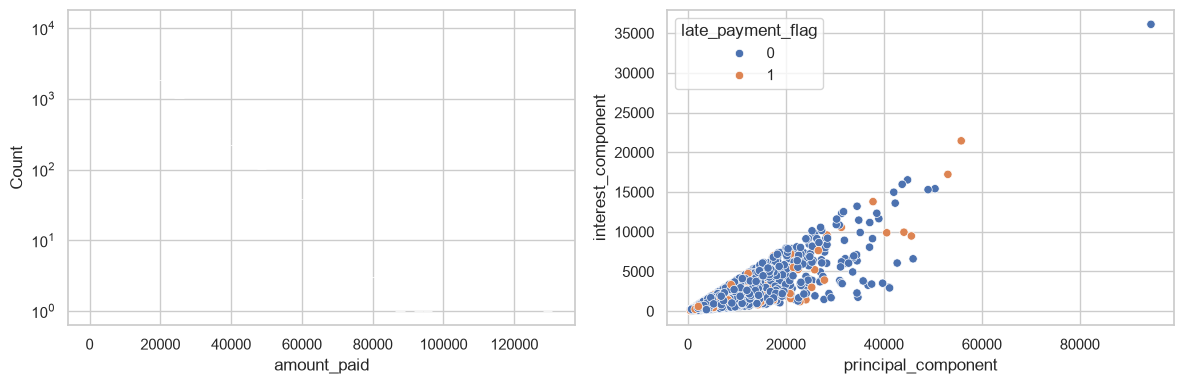

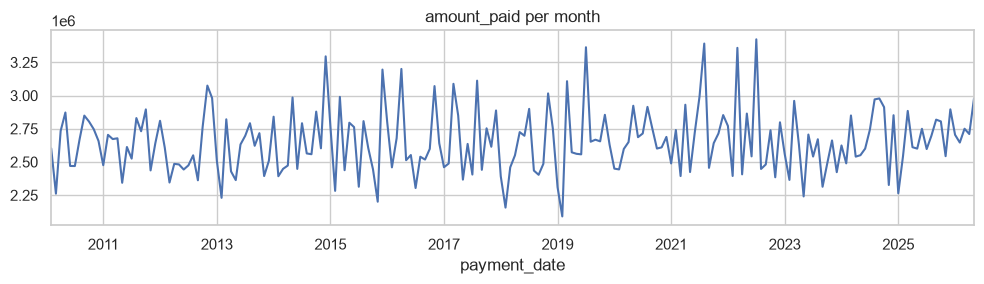

In [6]:
profile(payments, "loan_payments")
print("late-payment rate:", (payments["late_payment_flag"] == 1).mean().round(4))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(payments["amount_paid"], bins=50, log_scale=(False, True), ax=axes[0])
sns.scatterplot(data=payments.sample(2000, random_state=42),
                x="principal_component", y="interest_component", hue="late_payment_flag", ax=axes[1])
plt.tight_layout(); plt.show()
payments.set_index("payment_date").resample("ME")["amount_paid"].sum().plot(
    figsize=(10, 3), title="amount_paid per month")
plt.tight_layout(); plt.show()

### transactions (50k sample)

--- transactions ---
shape: (50000, 9)
                                     dtype  nulls  null_pct
transaction_id                       int64      0       0.0
account_id                           int64      0       0.0
txn_date                     datetime64[s]      0       0.0
txn_type                               str      0       0.0
amount                             float64      0       0.0
channel                                str      0       0.0
merchant_category                      str      0       0.0
loaded_at          datetime64[us, Etc/UTC]      0       0.0
created_at         datetime64[us, Etc/UTC]      0       0.0


,transaction_id,account_id,txn_date,txn_type,amount,channel,merchant_category,loaded_at,created_at
0,1,42369,2018-03-13,Deposit,1817.91,Online Banking,Salary Credit,2026-10-16 06:22:24.155486+00:00,2026-10-16 06:22:24.155486+00:00
1,2,53934,2022-03-05,Withdrawal,12855.96,Mobile App,ATM Withdrawal,2026-10-16 06:22:24.155486+00:00,2026-10-16 06:22:24.155486+00:00
2,3,53478,2022-05-29,Deposit,8278.61,UPI,Education,2026-10-16 06:22:24.155486+00:00,2026-10-16 06:22:24.155486+00:00


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
transaction_id,50000.0,NaN,NaN,NaN,25000.5,1.0,12500.75,25000.5,37500.25,50000.0,14433.901067
account_id,50000.0,NaN,NaN,NaN,47592.48164,1.0,24016.5,47529.0,71375.25,95000.0,27402.507133
txn_date,50000,NaN,NaN,NaN,2022-04-03 07:34:24,2018-01-01 00:00:00,2020-02-18 00:00:00,2022-04-11 00:00:00,2024-05-12 00:00:00,2026-06-30 00:00:00,NaN
txn_type,50000,6,Deposit,12526,NaN,NaN,NaN,NaN,NaN,NaN,NaN
amount,50000.0,NaN,NaN,NaN,6062.190816,50.27,1783.7775,4251.275,8392.3975,63126.64,5995.776393
channel,50000,6,Branch,8411,NaN,NaN,NaN,NaN,NaN,NaN,NaN
merchant_category,50000,14,Salary Credit,3663,NaN,NaN,NaN,NaN,NaN,NaN,NaN
loaded_at,50000,NaN,NaN,NaN,2026-10-16 06:22:24.155486+00:00,2026-10-16 06:22:24.155486+00:00,2026-10-16 06:22:24.155486+00:00,2026-10-16 06:22:24.155486+00:00,2026-10-16 06:22:24.155486+00:00,2026-10-16 06:22:24.155486+00:00,NaN
created_at,50000,NaN,NaN,NaN,2026-10-16 06:22:24.155486+00:00,2026-10-16 06:22:24.155486+00:00,2026-10-16 06:22:24.155486+00:00,2026-10-16 06:22:24.155486+00:00,2026-10-16 06:22:24.155486+00:00,2026-10-16 06:22:24.155486+00:00,NaN


no missing values


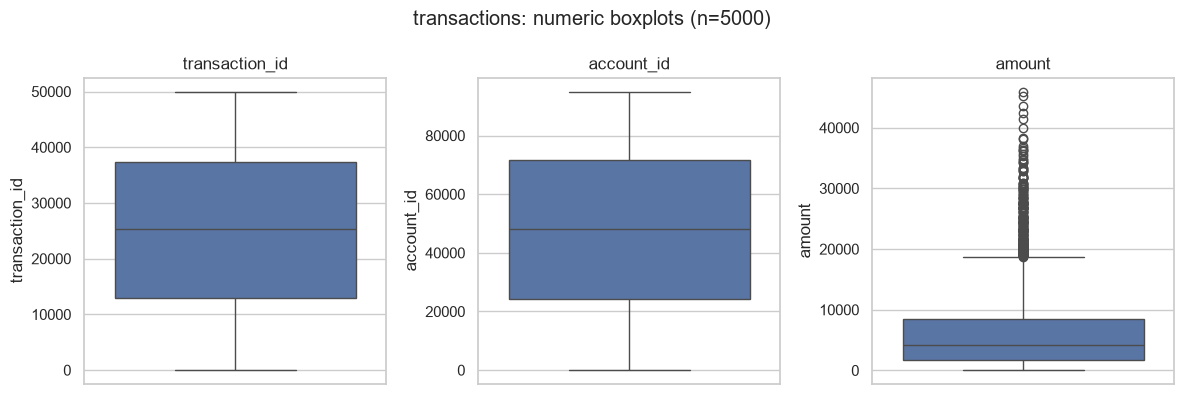

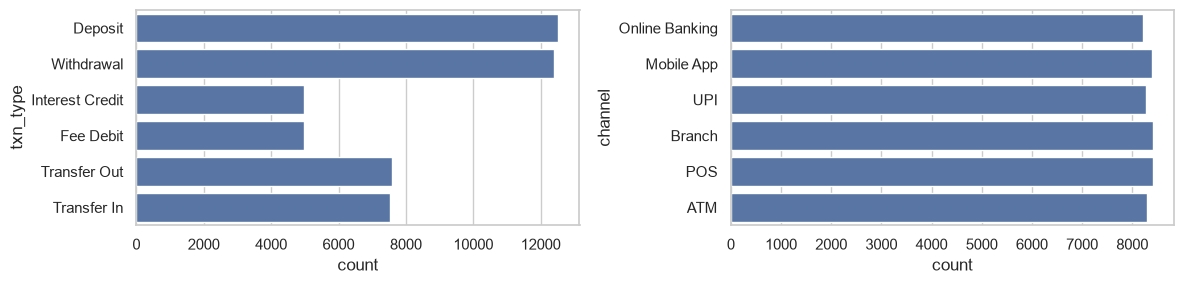

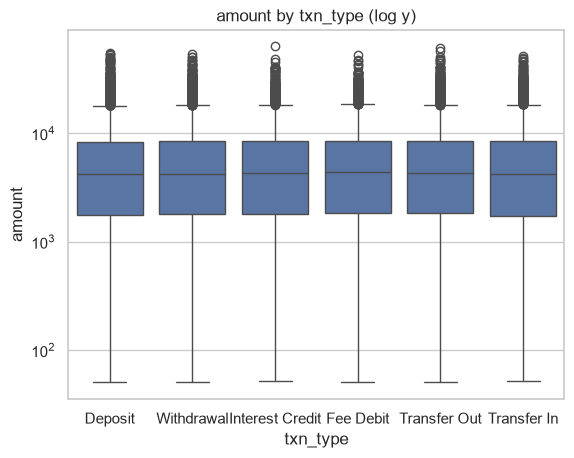

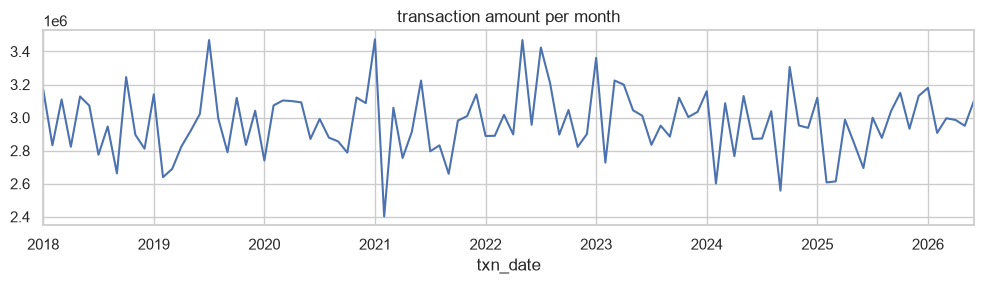

In [7]:
profile(txns, "transactions")
fig, axes = plt.subplots(1, 2, figsize=(12, 3))
sns.countplot(y=txns["txn_type"], ax=axes[0])
sns.countplot(y=txns["channel"], ax=axes[1])
plt.tight_layout(); plt.show()
sns.boxplot(data=txns, x="txn_type", y="amount")
plt.yscale("log"); plt.title("amount by txn_type (log y)"); plt.show()
txns.set_index("txn_date").resample("ME")["amount"].sum().plot(
    figsize=(10, 3), title="transaction amount per month")
plt.tight_layout(); plt.show()